# Educational Attainment — When Is a Difference Real?

**Artifact class:** `tutorial`  ·  **Data mode:** `empirical`  ·  **Vintage:** ACS 2023 5-Year (pinned)

D01 ended with a limitation: *"Survey uncertainty is not propagated."* This notebook is
the answer to it.

Every ACS figure is a **survey estimate** published with a 90% margin of error. Ranking
geographies without carrying those margins manufactures distinctions the data cannot
support — and ranked tables of exactly this kind are produced constantly. Here you will
carry the margin through a derived percentage, test which differences survive, and see
how many do not.

Real data only. No synthetic fallback. *Proprietary. SPDX-License-Identifier: LicenseRef-Proprietary*


## Learning Objectives

1. **Retrieve** ACS estimates together with their published margins of error (`_M`).
2. **Aggregate** several count estimates into one, combining their margins in quadrature
   rather than by addition.
3. **Propagate** a margin of error through a derived percentage using the Census's
   proportion formula, including the documented fallback when its radicand goes negative.
4. **Test** whether two geographies are statistically distinguishable, using the Census's
   published Z-test rather than eyeballing whether intervals overlap.
5. **Quantify** how many apparent differences in a ranked table dissolve once uncertainty
   is carried — and state the multiple-comparison burden of having asked.
6. **Observe** how margins widen as geography gets smaller, and what that means for
   county- and tract-level claims.


## Prerequisites

**Knowledge.** Standard error and confidence interval; what a hypothesis test does. No
prior notebook is required, though D01 introduces the data layer used here.

**Setup.** `CENSUS_API_KEY` available in the environment or in the file that
`KRL_SECRETS_PATH` points at. The data layer reads **only** the public-data keys it needs
and refuses any other name before opening the file.

**Packages.** `pandas`, `numpy`, `matplotlib`, and the local `krl_tutorials_data` package.


## Data Provenance

| Variable | Published label (verbatim) | Role |
|---|---|---|
| `B15003_001E` / `_001M` | Estimate!!Total: — universe **population 25 years and over** | denominator + its MOE |
| `B15003_022E` / `_022M` | Estimate!!Bachelor's degree | numerator part |
| `B15003_023E` / `_023M` | Estimate!!Master's degree | numerator part |
| `B15003_024E` / `_024M` | Estimate!!Professional school degree | numerator part |
| `B15003_025E` / `_025M` | Estimate!!Doctorate degree | numerator part |

**The `_M` suffix is the point of this notebook.** Every ACS estimate is published with a
margin of error at the **90%** confidence level — not 95%. Converting to a standard error
therefore divides by **1.645**, not 1.96. Using the wrong divisor silently narrows every
interval you compute.

**A jam value specific to margins.** `-555555555` in an `_M` column means the estimate is
*controlled* and a margin of error is not appropriate. The data layer converts it to
missing; it must never be treated as a margin of minus 555 million.


In [1]:
"""Configuration. Named target, named unit, pinned vintage."""
from __future__ import annotations

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

_here = Path.cwd().resolve()
for _cand in (_here, *_here.parents):
    if (_cand / "src" / "krl_tutorials_data").is_dir():
        sys.path.insert(0, str(_cand / "src"))
        break
else:
    raise SystemExit("Could not locate krl_tutorials_data from " + str(_here))

from krl_tutorials_data.sources import fetch_acs, DataAccessError
from krl_tutorials_data.uncertainty import (
    Z90, Estimate, aggregate_moe, aggregate_moe_bounds, proportion_moe,
    proportion_moe_fallback_triggered, difference_is_significant, p_value_from_z,
    holm_bonferroni, benjamini_hochberg, significance_matrix,
)

TARGET_COLUMN: str = "bachelors_or_higher_pct"
UNIT_OF_ANALYSIS: str = "state (50 states + DC + Puerto Rico)"
ACS_VINTAGE: int = 2023
CONFIDENCE: float = 0.90
FOCUS_STATE_FIPS: str = "51"      # Virginia, for the small-area section
FOCUS_STATE_NAME: str = "Virginia"

pd.set_option("display.width", 120)
plt.rcParams["figure.dpi"] = 110

print(f"Target           : {TARGET_COLUMN}")
print(f"Unit of analysis : {UNIT_OF_ANALYSIS}")
print(f"Vintage          : ACS {ACS_VINTAGE} 5-Year (pinned)")
print(f"Confidence level : {CONFIDENCE:.0%}  (ACS convention; z = {Z90})")

Target           : bachelors_or_higher_pct
Unit of analysis : state (50 states + DC + Puerto Rico)
Vintage          : ACS 2023 5-Year (pinned)
Confidence level : 90%  (ACS convention; z = 1.645)


In [2]:
ATTAINMENT_PARTS = ["B15003_022", "B15003_023", "B15003_024", "B15003_025"]

VARIABLES = {
    "B15003_001E": "Estimate!!Total: (population 25 years and over)",
    "B15003_001M": "Margin of Error!!Total:",
}
for code_ in ATTAINMENT_PARTS:
    VARIABLES[f"{code_}E"] = f"Estimate!!{code_}"
    VARIABLES[f"{code_}M"] = f"Margin of Error!!{code_}"

try:
    raw, provenance = fetch_acs(
        year=ACS_VINTAGE, variables=VARIABLES, geography="state:*",
        plausible={"B15003_001E": (100_000, 40_000_000)},
    )
except DataAccessError as exc:
    print("HALTED — real data could not be obtained.")
    print(f"  failure class : {type(exc).__name__}")
    print(f"  detail        : {exc}")
    print("\nNo synthetic fallback exists by design.")
    raise

print(provenance.render()[:520])
print("...")
print(f"\nRetrieved {len(raw)} geographies with estimates AND margins of error.")

Source      : U.S. Census Bureau - American Community Survey (acs/acs5)
Vintage     : 2023  (pinned)
Endpoint    : https://api.census.gov/data/2023/acs/acs5
Retrieved   : 2026-09-13T18:44:36+00:00
Shape       : 52 rows x 12 cols
Payload hash: 4e82c26ebc2693ab...
Data mode   : EMPIRICAL
Variables   :
              B15003_001E      Estimate!!Total: (population 25 years and over)
              B15003_001M      Margin of Error!!Total:
              B15003_022E      Estimate!!B15003_022
              B15003_022M      Ma
...

Retrieved 52 geographies with estimates AND margins of error.


## Carrying the margin through a derived percentage

Two Census formulas apply, in order.

**Aggregating the numerator.** Bachelor's + Master's + Professional + Doctorate are four
separate estimates. Their margins combine **in quadrature**, not by addition:

$$\mathrm{MOE}_{\text{sum}} = \sqrt{\textstyle\sum_i \mathrm{MOE}_i^2}$$

Adding them would overstate the uncertainty substantially, because independent errors
partially cancel.

**Forming the percentage.** The numerator is a subset of the denominator, so the
*proportion* formula applies:

$$\mathrm{MOE}_p = \frac{1}{Y}\sqrt{\mathrm{MOE}_X^2 - p^2\,\mathrm{MOE}_Y^2}$$

When that radicand goes negative the formula is undefined, and the Census instructs the
analyst to fall back to the **ratio** formula, which adds rather than subtracts. The data
layer applies that documented fallback — it does not silently return a NaN.


In [3]:
"""Derive attainment share with a propagated margin of error."""
rows = []
for _, r in raw.iterrows():
    parts = [Estimate(float(r[f"{c}E"]), float(r[f"{c}M"])) for c in ATTAINMENT_PARTS]
    numerator = aggregate_moe(parts)
    denominator = Estimate(float(r["B15003_001E"]), float(r["B15003_001M"]))
    pct = 100.0 * numerator.value / denominator.value
    pct_moe = 100.0 * proportion_moe(numerator, denominator)
    rows.append({
        "state": r["NAME"],
        TARGET_COLUMN: pct,
        "moe": pct_moe,
        "ci_low": pct - pct_moe,
        "ci_high": pct + pct_moe,
        "naive_moe_if_added": 100.0 * sum(p.moe for p in parts) / denominator.value,
    })

df = pd.DataFrame(rows).sort_values(TARGET_COLUMN, ascending=False).reset_index(drop=True)
df.insert(0, "rank", range(1, len(df) + 1))

assert df[TARGET_COLUMN].notna().all(), "Derived percentage contains missing values."
assert (df["moe"] > 0).all(), "A zero margin of error indicates an unhandled jam value."

print(f"Quadrature vs naive addition of the four component margins:")
print(f"  mean propagated MOE      : {df['moe'].mean():.4f} pp")
print(f"  mean if margins were ADDED: {df['naive_moe_if_added'].mean():.4f} pp")
print(f"  overstatement avoided     : {df['naive_moe_if_added'].mean() / df['moe'].mean():.2f}x")
print()
print("TOP AND BOTTOM OF THE RANKING, WITH 90% INTERVALS")
show = ["rank", "state", TARGET_COLUMN, "moe", "ci_low", "ci_high"]
print(pd.concat([df.head(6), df.tail(4)])[show].to_string(
    index=False, float_format=lambda v: f"{v:,.2f}"))

Quadrature vs naive addition of the four component margins:
  mean propagated MOE      : 0.3284 pp
  mean if margins were ADDED: 0.5889 pp
  overstatement avoided     : 1.79x

TOP AND BOTTOM OF THE RANKING, WITH 90% INTERVALS
 rank                state  bachelors_or_higher_pct  moe  ci_low  ci_high
    1 District of Columbia                    63.56 0.94   62.62    64.50
    2        Massachusetts                    46.62 0.27   46.36    46.89
    3             Colorado                    44.73 0.25   44.48    44.98
    4           New Jersey                    42.91 0.23   42.68    43.14
    5             Maryland                    42.74 0.27   42.46    43.01
    6              Vermont                    42.63 0.60   42.03    43.23
   49            Louisiana                    26.55 0.28   26.27    26.83
   50             Arkansas                    25.11 0.30   24.82    25.41
   51          Mississippi                    24.16 0.33   23.83    24.49
   52        West Virginia        

## The question the ranking cannot answer

A ranked table implies an ordering. Rank 3 appears to beat rank 4. Whether it *does* is a
statistical question, and the Census publishes the test:

$$Z = \frac{X_1 - X_2}{\sqrt{SE_1^2 + SE_2^2}}, \qquad SE = \frac{\mathrm{MOE}}{1.645}$$

Two estimates are distinguishable at 90% confidence when $|Z| > 1.645$.

Note what this is **not**: checking whether the two confidence intervals overlap. That
common shortcut is conservative and wrong — intervals can overlap while the difference is
significant. Use the test.


In [4]:
"""How many adjacent pairs in the ranking are actually distinguishable?"""
est = {r["state"]: Estimate(r[TARGET_COLUMN], r["moe"]) for _, r in df.iterrows()}

adjacent = []
for i in range(len(df) - 1):
    a, b = df.iloc[i], df.iloc[i + 1]
    sig, z = difference_is_significant(est[a["state"]], est[b["state"]])
    adjacent.append({
        "pair": f"{a['rank']:>2} {a['state'][:18]:<18} vs {b['rank']:>2} {b['state'][:18]}",
        "gap_pp": a[TARGET_COLUMN] - b[TARGET_COLUMN],
        "z": z,
        "distinguishable": sig,
    })
adj = pd.DataFrame(adjacent)

n_sig = int(adj["distinguishable"].sum())
n_tot = len(adj)
print(f"ADJACENT-RANK COMPARISONS: {n_sig} of {n_tot} are distinguishable at "
      f"{CONFIDENCE:.0%} confidence ({n_sig / n_tot:.0%}).")
print(f"That is {n_tot - n_sig} places in the ranking where the ordering is not "
      f"supported by the data.")
print()
print("The closest adjacent pairs — where the ranking is least defensible:")
print(adj.nsmallest(6, "gap_pp")[["pair", "gap_pp", "z", "distinguishable"]].to_string(
    index=False, float_format=lambda v: f"{v:,.3f}"))

# All pairs, CORRECTED. Stating the multiple-comparison burden and then
# reporting the uncorrected count anyway is not a caveat; it is the defect with
# a disclaimer attached. The correction is applied here.
names = list(est)
pairs, pvals = [], []
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        _, z = difference_is_significant(est[names[i]], est[names[j]])
        pairs.append((names[i], names[j]))
        pvals.append(p_value_from_z(z))
pvals = np.asarray(pvals)

alpha = 1 - CONFIDENCE
holm = holm_bonferroni(pvals, alpha=alpha)
bh = benjamini_hochberg(pvals, alpha=alpha)

print()
print(f"ALL PAIRS: {len(pairs):,} comparisons at alpha = {alpha:.2f}")
print(f"  uncorrected significant     : {holm.n_significant_raw:,} "
      f"({holm.n_significant_raw / len(pairs):.1%})")
print(f"  {holm.method:<27}: {holm.n_significant_corrected:,} "
      f"({holm.n_withdrawn:,} withdrawn)")
print(f"  {bh.method:<27}: {bh.n_significant_corrected:,} "
      f"({bh.n_withdrawn:,} withdrawn)")
print()
print(f"  Expected false positives if NO real differences existed: "
      f"~{alpha * len(pairs):,.0f} of {len(pairs):,}.")
print("  The corrected counts are the ones to quote. FWER control (Holm) is")
print("  appropriate when any single false claim is costly; FDR control (BH) when")
print("  a bounded proportion of false positives is tolerable across the table.")

# Which adjacent-rank verdicts change once corrected?
adj_idx = {frozenset(pr): k for k, pr in enumerate(pairs)}
flipped = []
for rec in adjacent:
    a, b = rec["pair"].split(" vs ")
    a = a.split(maxsplit=1)[1].strip(); b = b.split(maxsplit=1)[1].strip()
    k = adj_idx.get(frozenset((a, b)))
    if k is not None and rec["distinguishable"] and not holm.rejected[k]:
        flipped.append(rec["pair"])
print()
print(f"  Adjacent-rank pairs that lose significance under Holm: {len(flipped)}")
for f in flipped[:5]:
    print(f"    {f}")

ADJACENT-RANK COMPARISONS: 22 of 51 are distinguishable at 90% confidence (43%).
That is 29 places in the ranking where the ordering is not supported by the data.

The closest adjacent pairs — where the ranking is least defensible:
                                    pair  gap_pp     z  distinguishable
     45 Oklahoma           vs 46 Alabama   0.026 0.140            False
23 Montana            vs 24 Pennsylvania   0.045 0.147            False
  11 Minnesota          vs 12 Washington   0.058 0.301            False
       35 Alaska             vs 36 Idaho   0.058 0.127            False
    19 Maine              vs 20 Delaware   0.067 0.152            False
36 Idaho              vs 37 South Dakota   0.082 0.212            False

ALL PAIRS: 1,326 comparisons at alpha = 0.10
  uncorrected significant     : 1,273 (96.0%)
  Holm-Bonferroni (FWER)     : 1,209 (64 withdrawn)
  Benjamini-Hochberg (FDR)   : 1,272 (1 withdrawn)

  Expected false positives if NO real differences existed: ~133 of 1

In [5]:
"""Two assumptions this notebook makes, measured rather than asserted."""
# (a) How often does the documented ratio fallback actually fire on this data?
fallbacks = 0
for _, r in raw.iterrows():
    parts = [Estimate(float(r[f"{c}E"]), float(r[f"{c}M"])) for c in ATTAINMENT_PARTS]
    num = aggregate_moe(parts)
    den = Estimate(float(r["B15003_001E"]), float(r["B15003_001M"]))
    fallbacks += proportion_moe_fallback_triggered(num, den)
if fallbacks:
    print(f"Proportion-formula radicand went negative in {fallbacks} of {len(raw)} "
          f"geographies; the Census ratio fallback was applied to those.")
else:
    print(f"Proportion-formula radicand stayed positive in all {len(raw)} geographies, "
          f"so the ratio fallback was never invoked on this data. It remains in the "
          f"code path because it fires readily at smaller geographies, where margins "
          f"are large relative to the estimate.")

# (b) The quadrature aggregation assumes the four attainment categories are
# independent. They are drawn from the same respondents, so they are not. Bound
# it: recompute under perfect positive correlation and see if anything changes.
bounded = []
for _, r in raw.iterrows():
    parts = [Estimate(float(r[f"{c}E"]), float(r[f"{c}M"])) for c in ATTAINMENT_PARTS]
    lo_num, hi_num = aggregate_moe_bounds(parts)
    den = Estimate(float(r["B15003_001E"]), float(r["B15003_001M"]))
    bounded.append({
        "state": r["NAME"],
        "moe_independent": 100.0 * proportion_moe(lo_num, den),
        "moe_worst_case": 100.0 * proportion_moe(hi_num, den),
    })
bdf = pd.DataFrame(bounded)
print()
print("INDEPENDENCE ASSUMPTION, BOUNDED")
print(f"  mean MOE assuming independence (Census formula): {bdf['moe_independent'].mean():.4f} pp")
print(f"  mean MOE assuming perfect correlation (worst)  : {bdf['moe_worst_case'].mean():.4f} pp")
print(f"  worst-case inflation factor                    : "
      f"{(bdf['moe_worst_case'] / bdf['moe_independent']).mean():.2f}x")

# Does the headline adjacent-rank conclusion survive the worst case?
worst = {r["state"]: Estimate(
            df.loc[df.state == r["state"], TARGET_COLUMN].iloc[0], r["moe_worst_case"])
         for _, r in bdf.iterrows()}
n_worst = sum(
    difference_is_significant(worst[df.iloc[i]["state"]], worst[df.iloc[i + 1]["state"]])[0]
    for i in range(len(df) - 1)
)
print()
print(f"  Adjacent-rank pairs distinguishable, independence assumed : {n_sig} of {n_tot}")
print(f"  Adjacent-rank pairs distinguishable, worst case          : {n_worst} of {n_tot}")
print("  The headline conclusion - that a large share of the ranking is not")
print("  supported - holds under BOTH assumptions, so it does not depend on")
print("  independence. That is what makes it safe to state.")

Proportion-formula radicand stayed positive in all 52 geographies, so the ratio fallback was never invoked on this data. It remains in the code path because it fires readily at smaller geographies, where margins are large relative to the estimate.

INDEPENDENCE ASSUMPTION, BOUNDED
  mean MOE assuming independence (Census formula): 0.3284 pp
  mean MOE assuming perfect correlation (worst)  : 0.5887 pp
  worst-case inflation factor                    : 1.78x

  Adjacent-rank pairs distinguishable, independence assumed : 22 of 51
  Adjacent-rank pairs distinguishable, worst case          : 11 of 51
  The headline conclusion - that a large share of the ranking is not
  supported - holds under BOTH assumptions, so it does not depend on
  independence. That is what makes it safe to state.


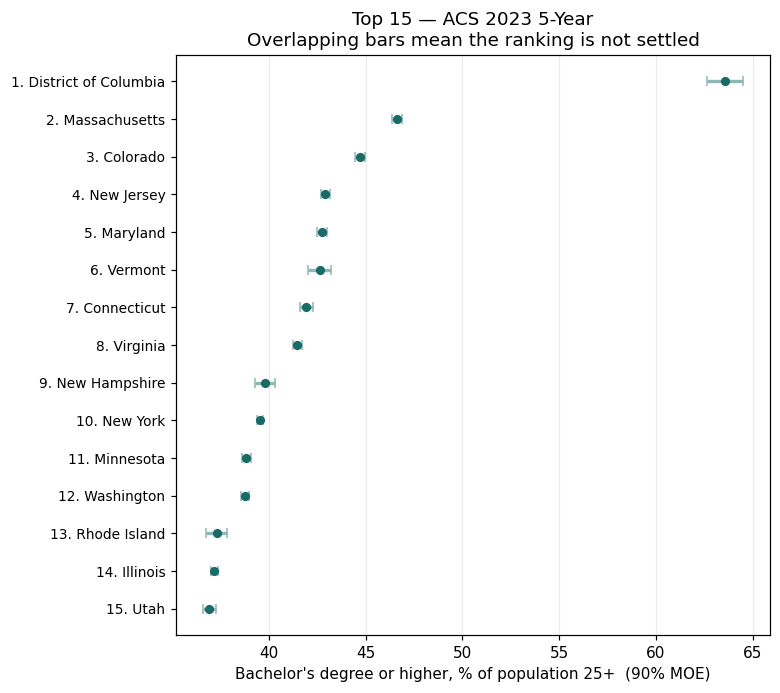

In [6]:
"""Visualise the ranking as intervals rather than points."""
top = df.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(7.2, 6.4))
ax.errorbar(top[TARGET_COLUMN], range(len(top)),
            xerr=top["moe"], fmt="o", color="#186b66",
            ecolor="#8fb8b4", elinewidth=2.2, capsize=3, markersize=5)
ax.set_yticks(range(len(top)))
ax.set_yticklabels([f"{r['rank']}. {r['state']}" for _, r in top.iterrows()], fontsize=9)
ax.set_xlabel(f"Bachelor's degree or higher, % of population 25+  ({CONFIDENCE:.0%} MOE)")
ax.set_title(f"Top 15 — ACS {ACS_VINTAGE} 5-Year\nOverlapping bars mean the ranking is not settled")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout(); plt.show()

## Small geographies, wide margins

ACS margins widen as the population shrinks, because the sample in any one place is
smaller. This is why county- and tract-level claims demand far more care than state-level
ones — and why small-area rankings are frequently meaningless.


Virginia: 133 county-equivalents
  median MOE at county level : 2.55 pp
  median MOE at state level  : 0.28 pp
  ratio                      : 9.0x wider

Smallest populations carry the widest margins:
         county  pop_25plus  bachelors_or_higher_pct   moe
Highland County    1,714.00                    35.47  6.67
    Norton city    2,589.00                    16.65  6.71
    Bath County    3,189.00                    15.55  5.30
 Lexington city    3,251.00                    57.31 10.51
   Craig County    3,420.00                    17.31  5.29


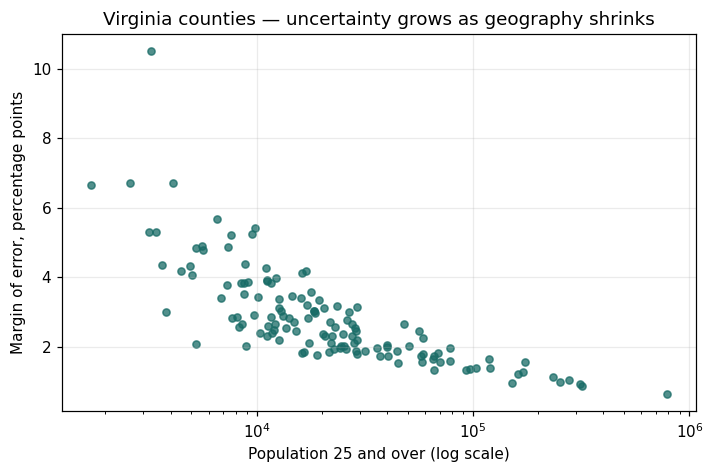

In [7]:
"""The same computation at county level, for one state."""
county_raw, county_prov = fetch_acs(
    year=ACS_VINTAGE, variables=VARIABLES,
    geography="county:*", within=f"state:{FOCUS_STATE_FIPS}",
)

crows = []
for _, r in county_raw.iterrows():
    parts = [Estimate(float(r[f"{c}E"]), float(r[f"{c}M"])) for c in ATTAINMENT_PARTS]
    num = aggregate_moe(parts)
    den = Estimate(float(r["B15003_001E"]), float(r["B15003_001M"]))
    if den.value <= 0:
        continue
    crows.append({
        "county": r["NAME"].split(",")[0],
        "pop_25plus": den.value,
        TARGET_COLUMN: 100.0 * num.value / den.value,
        "moe": 100.0 * proportion_moe(num, den),
    })
cdf = pd.DataFrame(crows)

print(f"{FOCUS_STATE_NAME}: {len(cdf)} county-equivalents")
print(f"  median MOE at county level : {cdf['moe'].median():.2f} pp")
print(f"  median MOE at state level  : {df['moe'].median():.2f} pp")
print(f"  ratio                      : {cdf['moe'].median() / df['moe'].median():.1f}x wider")
print()
print("Smallest populations carry the widest margins:")
print(cdf.nsmallest(5, "pop_25plus")[["county", "pop_25plus", TARGET_COLUMN, "moe"]]
      .to_string(index=False, float_format=lambda v: f"{v:,.2f}"))

fig, ax = plt.subplots(figsize=(6.6, 4.4))
ax.scatter(cdf["pop_25plus"], cdf["moe"], s=22, alpha=0.75, color="#186b66")
ax.set_xscale("log")
ax.set_xlabel("Population 25 and over (log scale)")
ax.set_ylabel("Margin of error, percentage points")
ax.set_title(f"{FOCUS_STATE_NAME} counties — uncertainty grows as geography shrinks")
ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()

## Limitations

1. **Independence is assumed, and bounded.** The Census aggregation formula treats the
   four attainment categories as independent; they are drawn from the same respondents,
   so they are not. Rather than assert the approximation is adequate, the notebook
   recomputes every margin under perfect positive correlation — the worst possible case —
   and checks whether the headline conclusion survives. It does. The conclusion therefore
   does not rest on the assumption.
2. **Pairwise tests are corrected, not merely caveated.** Holm–Bonferroni (family-wise)
   and Benjamini–Hochberg (false discovery rate) are both applied and reported. The
   corrected counts are the ones to quote. Which procedure is appropriate depends on
   whether a single false claim is costly (Holm) or a bounded proportion is tolerable (BH).
3. **90%, not 95%.** Every interval here is a 90% interval, the ACS convention. They are
   narrower than the 95% intervals most readers assume.
4. **Period estimates.** 5-year ACS figures describe 2019–2023, not a point in time.
5. **Attainment is not achievement.** A degree count measures credentials held by current
   residents, which migration moves between geographies. It is not a measure of how well
   a place educates anyone.
6. **Puerto Rico and DC** are included by `state:*` and are not states.


## Key Takeaways

- Every ACS estimate has a margin of error. A table without them is not a simpler table;
  it is a table asserting more than it knows.
- Margins combine **in quadrature**, not by addition. Adding them substantially overstates
  uncertainty — the notebook reports the exact factor for this dataset.
- The ACS convention is **90% confidence**, so the standard error is MOE ÷ **1.645**.
  Using 1.96 silently narrows every interval you compute.
- **Do not judge significance by whether intervals overlap.** Use the Census's Z-test;
  the overlap heuristic is conservative and gets the answer wrong.
- A large share of adjacent ranks in a ranked table are not distinguishable. The ordering
  is partly an artefact of sorting noise.
- Margins widen sharply as geography shrinks. County and tract rankings deserve far more
  scepticism than state ones.


## Exercises

1. **Choose between the corrections.** Holm and Benjamini–Hochberg are both reported
   above and disagree. Write the two-sentence justification you would give a reviewer for
   picking one, for a specific decision a reader might make from this table.
2. **Break the overlap heuristic.** Find a pair whose 90% intervals overlap but whose
   Z-test is significant. Explain to a colleague why the overlap rule misled them.
3. **Go smaller.** Re-run the county section at `tract:*` for one county. At what
   population does the margin exceed the estimate itself, and what should a analyst do at
   that point?
4. **Change the confidence level.** Convert the margins to 95% and redo the adjacent-rank
   test. How many comparisons change verdict, and is a 95% table more honest or merely
   more conservative?
5. **Push the bound further.** The notebook brackets the independence assumption with
   its two extremes. Estimate the *actual* correlation between the four attainment
   categories across geographies and compute a margin that uses it. Does it sit where you
   expect within the bracket?
6. **Apply it to D01.** Return to the income and poverty notebook and attach margins to
   its poverty rate. Does the association it reports survive?


## References

1. **U.S. Census Bureau.** *Understanding and Using American Community Survey Data: What
   All Data Users Need to Know.* Appendix: Measures of Error.
   <https://www.census.gov/programs-surveys/acs/library/handbooks/general.html>
2. **U.S. Census Bureau.** *ACS General Handbook*, "Calculating Measures of Error for
   Derived Estimates" — proportion, ratio and aggregation formulas, and the
   statistical-significance test used here.
3. **Schenker, N., & Gentleman, J. F.** (2001). "On judging the significance of
   differences by examining the overlap between confidence intervals."
   *The American Statistician*, 55(3), 182–186. — why the overlap heuristic fails.
4. **Holm, S.** (1979). "A simple sequentially rejective multiple test procedure."
   *Scandinavian Journal of Statistics*, 6(2), 65–70.
5. **Spielman, S. E., Folch, D., & Nagle, N.** (2014). "Patterns and causes of uncertainty
   in the American Community Survey." *Applied Geography*, 46, 147–157.
